# Week 11 — Visualization I: Dask and Datashader

Read partitioned data, aggregate points into pixels, and compare density and category maps.

**Examples:** OpenStreetMap GPS points and historical Census dots.

<a href="Visualizing%20Large%20Data-Lec1.ipynb" download>Download notebook</a> · [Next: Visualization II](Visualizing%20Large%20Data-Lec2.html) · [LiDAR processing](lecture-11B.html)


## Before you start

Use the dedicated **Python (largeviz)** environment for this notebook. Download <a href="environment-viz.yml" download>environment-viz.yml</a> beside the notebook, then run these commands in a terminal opened in that folder:

```bash
# First time: create the environment from the package list.
conda env create -f environment-viz.yml

# If largeviz already exists, update it instead of creating it again:
# conda env update -n largeviz -f environment-viz.yml

conda activate largeviz
python -m ipykernel install --user --name largeviz --display-name "Python (largeviz)"
jupyter lab
```

Select **Python (largeviz)** in Jupyter or VS Code, then run the cells from top to bottom. The YAML package list includes `pyarrow`, `geopandas`, and `pyogrio` for the Parquet-to-GeoPackage demo. If you previously created `largeviz`, run the update command above and restart the notebook kernel to pick up the added packages. Keep package changes in `environment-viz.yml` so everyone uses the same setup.


## Download the data first

1. Create a local folder named `week11` and save <a href="Visualizing%20Large%20Data-Lec1.ipynb" download>this notebook</a> and <a href="environment-viz.yml" download>environment-viz.yml</a> there.
2. Create `data/samples/` inside `week11`.
3. Download each file below into that folder. Keep the exact filename. If a link opens in the browser, right-click and choose **Save Link As…**.

| Download | Save locally as |
| --- | --- |
| [osm_sample.parquet](data/samples/osm_sample.parquet) | `data/samples/osm_sample.parquet` |
| [census_sample.parquet](data/samples/census_sample.parquet) | `data/samples/census_sample.parquet` |

Open the notebook from `week11` and select **Python (largeviz)**. Paths below are relative to that folder. Files are read locally; no automatic downloads or hidden caches are used.

The files are teaching extracts, not the full billion-point archives or representative population/travel estimates. Census dots have synthetic locations. See [sources and sampling](data/samples/provenance.json). For a full local Parquet dataset, change its filename below to your Parquet folder; keep the lazy Dask workflow.


## 1. Import the packages

Dask handles partitioned tables; Datashader converts point counts into a fixed-size image. Colorcet provides color maps.


In [2]:
ls

__pycache__/                       lecture-presentation.css
_quarto.yml                        lidar_workflow.py
data/                              make_lidar_figures.py
dsm_tools.py                       outputs/
environment-lidar.yml              pdal-las2desm.py
environment-viz.yml                README.md
imgs/                              usgs_pdal_dsm.py
las2raster.py                      validate_outputs.py
lecture-11A_files/                 Visualizing Large Data-Lec1_files/
lecture-11A.html                   Visualizing Large Data-Lec1.html
lecture-11A.ipynb                  Visualizing Large Data-Lec1.ipynb
lecture-11B_files/                 Visualizing Large Data-Lec2_files/
lecture-11B.html                   Visualizing Large Data-Lec2.html
lecture-11B.ipynb                  Visualizing Large Data-Lec2.ipynb


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import datashader as ds
import datashader.transfer_functions as tf
from datashader.utils import lnglat_to_meters
from colorcet import fire
import matplotlib.pyplot as plt
from IPython.display import display

# Files saved beside this notebook, following the folder layout above.
DATA = Path("data/samples")
OUT = Path("outputs/viz1")
OUT.mkdir(parents=True, exist_ok=True)
print("Datashader", ds.__version__, "| Dask", dask.__version__)

Datashader 0.18.2 | Dask 2025.9.1


## 1a. What is Parquet? Inspect it and export a QGIS demo

**Parquet is a binary, column-oriented table format.** Unlike CSV, it stores column types and supports compression. Data is organized into **row groups**, each containing chunks for the different columns. Readers can select columns and process batches instead of loading the whole table; Dask will use these features in Section 2.

| Format | What it stores | Role in this lesson |
| --- | --- | --- |
| CSV | Text rows and fields | Easy to inspect, but types and spatial metadata need interpretation |
| Parquet | Typed columns with compression and row groups | Efficient storage and selective reading of large tables |
| GeoParquet | Parquet with geometry and geographic metadata | Spatial tables with an explicitly described geometry/CRS |
| GeoPackage (`.gpkg`) | Vector geometry, attributes, and CRS in a SQLite file | A portable point layer for the QGIS demo |

Our [OSM teaching Parquet file](data/samples/osm_sample.parquet) contains numeric **`x` and `y` columns**, not a geometry column or GeoParquet metadata. The coordinates are **EPSG:3857 (Web Mercator), in meters**, as documented for this prepared dataset. Parquet itself does not imply a coordinate system. Do not label these values as EPSG:4326 longitude/latitude.

First inspect the schema and row-group metadata with PyArrow. This step reads metadata, not the entire million-row table.

In [3]:
import pyarrow.parquet as pq
import geopandas as gpd

parquet_path = DATA / "osm_sample.parquet"
parquet_file = pq.ParquetFile(parquet_path)
print("Columns and types:")
print(parquet_file.schema_arrow)
print(f"Rows: {parquet_file.metadata.num_rows:,}")
print("Row groups:", parquet_file.metadata.num_row_groups)
print(f"File size: {parquet_path.stat().st_size / 1_000_000:.1f} MB")

Columns and types:
x: float
y: float
-- schema metadata --
pandas: '{"columns": [{"metadata": null, "name": "x", "numpy_type": "floa' + 166
Rows: 1,000,050
Row groups: 21
File size: 11.7 MB


### Convert 10,000 points to GeoPackage

For a quick demonstration, read **at most 10,000 rows** using `iter_batches()`, selecting only `x` and `y`. This is a bounded preview of the file's first records, not a random or representative sample. We deliberately do not convert the full billion-point source archive.

Create point geometry from the coordinates, assign the known source CRS with `crs="EPSG:3857"`, and write a GeoPackage. Assigning a CRS describes the existing coordinates; it does not transform them. QGIS can reproject the layer for display.

In [4]:
DEMO_POINTS = 10_000
batch = next(parquet_file.iter_batches(batch_size=DEMO_POINTS, columns=["x", "y"]))
demo = batch.to_pandas()
demo = demo.replace([np.inf, -np.inf], np.nan).dropna(subset=["x", "y"])
if demo.empty:
    raise ValueError("The preview contains no valid coordinates.")

qgis_points = gpd.GeoDataFrame(
    demo,
    geometry=gpd.points_from_xy(demo["x"], demo["y"]),
    crs="EPSG:3857",
)
qgis_path = OUT / "osm_gps_qgis_demo.gpkg"
# Rerunning replaces this demonstration layer.
qgis_points.to_file(qgis_path, layer="osm_gps_demo", driver="GPKG", mode="w", index=False)
print(f"Exported {len(qgis_points):,} points to {qgis_path.resolve()}")
print("Layer: osm_gps_demo | CRS:", qgis_points.crs)
qgis_points.head()

Exported 10,000 points to /Users/jianglix/Dropbox/xiaojiang/Teaching/Penn/python-class/python-spatial-data-science/public/labs/week11-large-data-viz-lidar/outputs/viz1/osm_gps_qgis_demo.gpkg
Layer: osm_gps_demo | CRS: EPSG:3857


,x,y,geometry
0,-7000458.5,-9536415.0,POINT (-7000458.5 -9536415)
1,-7141858.0,-9664043.0,POINT (-7141858 -9664043)
2,-7379035.0,-9890349.0,POINT (-7379035 -9890349)
3,-7721307.5,-10498321.0,POINT (-7721307.5 -10498321)
4,-7514765.5,-7346013.0,POINT (-7514765.5 -7346013)


### Open the result in QGIS

1. Run the export cell above. It creates **`outputs/viz1/osm_gps_qgis_demo.gpkg`** beside the notebook's data folder.
2. Open QGIS and drag the `.gpkg` file from your file manager onto the map canvas. If prompted, choose the **`osm_gps_demo`** layer.
3. Right-click the layer → **Zoom to Layer**. Open its attribute table to inspect `x` and `y` and compare the row count with the printed export count.
4. Open **Layer Properties → Information** and confirm the layer CRS is **EPSG:3857**. The project may use a different CRS because QGIS reprojects layers for display. Close the layer before rerunning the export if QGIS locks the file.

The export contains individual points and their coordinates, not a density raster. The rest of this lesson keeps the original Parquet data and uses Dask/Datashader to aggregate it without creating one GIS feature for every source record.

References: [PyArrow Parquet reader and batch API](https://arrow.apache.org/docs/python/generated/pyarrow.parquet.ParquetFile.html) · [QGIS: opening vector data and GeoPackages](https://docs.qgis.org/latest/en/docs/user_manual/managing_data_source/opening_data.html).

## 2. Read GPS points with Dask

`read_parquet()` creates a lazy table. `head()` reads a few rows so we can inspect the columns.


In [5]:
osm = dd.read_parquet(DATA / "osm_sample.parquet", columns=["x", "y"],
                      engine="pyarrow", split_row_groups=True)
print("Partitions:", osm.npartitions)
osm.head()

Partitions: 21


,x,y
0,-7000458.5,-9536415.0
1,-7141858.0,-9664043.0
2,-7379035.0,-9890349.0
3,-7721307.5,-10498321.0
4,-7514765.5,-7346013.0


### Count the points

Use `dask.compute()` to calculate several summaries in one pass. The full table stays partitioned.


In [6]:
row_count, mean_x, mean_y = dask.compute(osm.shape[0], osm.x.mean(), osm.y.mean())
print(f"Extract rows: {row_count:,}; mean x={mean_x:,.0f}, y={mean_y:,.0f} meters")

Extract rows: 1,000,050; mean x=2,731,821, y=5,801,809 meters


### Aggregate points into pixels

Create a canvas, then count how many points fall in each pixel. The coordinates are Web Mercator meters; convert the map extent from longitude/latitude.


In [8]:
def mercator_extent(lon_bounds, lat_bounds):
    x, y = lnglat_to_meters(lon_bounds, lat_bounds)
    return tuple(x), tuple(y)

world_x, world_y = mercator_extent((-180, 180), (-70, 80))
canvas = ds.Canvas(plot_width=900, plot_height=450, x_range=world_x, y_range=world_y)
osm_count = canvas.points(osm, "x", "y", agg=ds.count())
print("Aggregate dimensions:", dict(osm_count.sizes))
print("Points inside this extent:", int(osm_count.sum()))

Aggregate dimensions: {'y': 450, 'x': 900}
Points inside this extent: 1000049


### Compare color scales

Shade the same counts three ways. Log and equalized scales reveal sparse areas; they change how counts map to color.


In [9]:
# fire[40:]

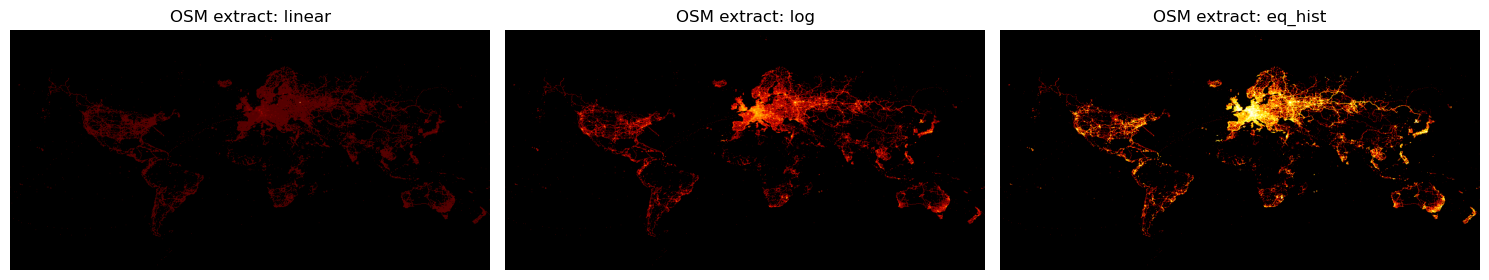

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, how in zip(axes, ["linear", "log", "eq_hist"]):
    image = tf.set_background(tf.shade(osm_count, cmap=fire[40:], how=how), "black")
    ax.imshow(image.to_pil())
    ax.set_title(f"OSM extract: {how}")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

### Save a density map

Hide pixels with two or fewer points and save the image. Try a different threshold.


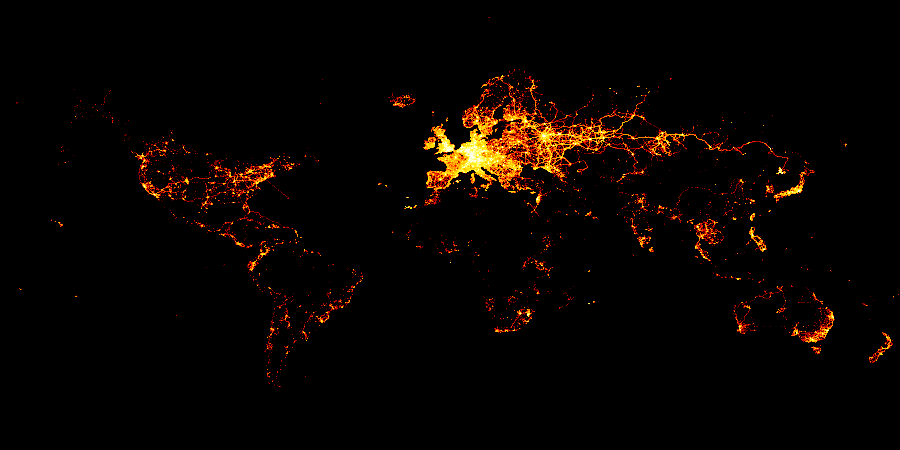

In [12]:
masked_osm = osm_count.where(osm_count > 2)
osm_image = tf.set_background(tf.shade(masked_osm, cmap=fire[40:], how="eq_hist"), "black")
osm_image.to_pil().save(OUT / "osm_density.png")
display(osm_image.to_pil())

## 3. Map Census categories

Read the Census extract and tell Datashader which categories to expect. `count_cat()` counts each category separately in every pixel. The labels come from the historical source data.


In [14]:
race_labels = {"w": "White", "b": "Black", "a": "Asian", "h": "Hispanic", "o": "Other"}
color_key = {"w": "#4cc9f0", "b": "#ffb703", "a": "#90be6d", "h": "#f28482", "o": "#cdb4db"}
census = dd.read_parquet(DATA / "census_sample.parquet", split_row_groups=True)
census["race"] = census["race"].astype(pd.CategoricalDtype(list(race_labels)))
census.head()

,easting,northing,race
0,-12352377.0,3676244.50,h
1,-12352691.0,3679306.75,h
2,-12352058.0,3677210.50,h
3,-12352007.0,3680322.75,h
4,-12351758.0,3677555.75,h


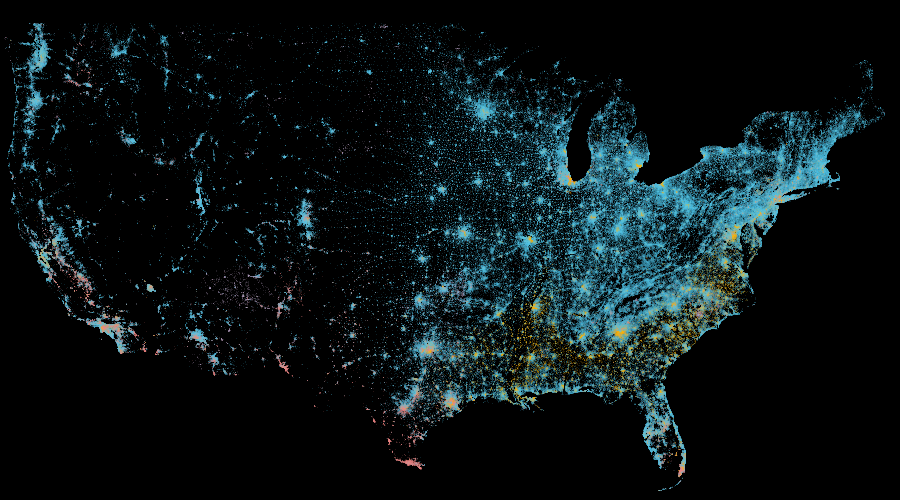

w       White
b       Black
a       Asian
h    Hispanic
o       Other
Name: Source category labels, dtype: object

In [15]:
usa_x, usa_y = mercator_extent((-125, -66), (24, 50))
census_canvas = ds.Canvas(plot_width=900, plot_height=500, x_range=usa_x, y_range=usa_y)
category_count = census_canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
census_image = tf.set_background(tf.shade(category_count, color_key=color_key, how="eq_hist"), "black")
display(census_image.to_pil())
pd.Series(race_labels, name="Source category labels")

### Map Census population density

Sum across categories, then compare linear and log color scales. These are counts of dots in the extract, not total population.


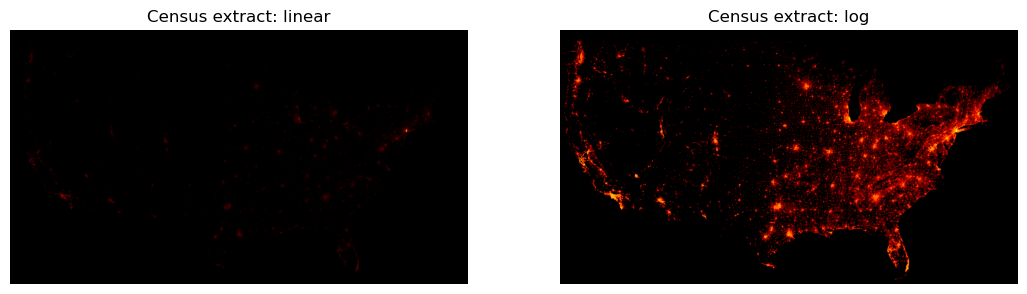

In [16]:
population = category_count.sum(dim="race")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, how in zip(axes, ["linear", "log"]):
    image = tf.set_background(tf.shade(population, cmap=fire, how=how), "black")
    ax.imshow(image.to_pil())
    ax.set_title(f"Census extract: {how}")
    ax.set_axis_off()
plt.show()


### Explore a city

Convert the longitude/latitude extent to Web Mercator with `lnglat_to_meters()`. Do not divide or multiply projected coordinates to imitate longitude/latitude. Datashader accepts planar coordinates; EPSG:3857 is used here to match the source data.


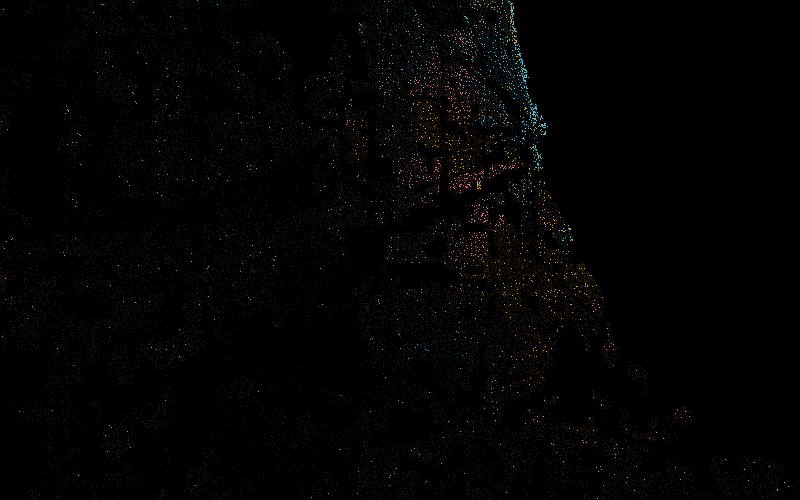

In [17]:
cities = {
    "USA": [(-125, -66), (24, 50)],
    "Chicago": [(-88.29, -87.30), (41.57, 42.00)],
    "New York": [(-74.39, -73.44), (40.51, 40.91)],
    "Philadelphia": [(-75.28, -74.96), (39.86, 40.14)],
    "Houston": [(-96.05, -94.68), (29.45, 30.11)],
}

def create_census_image(longitude_range, latitude_range):
    x_range, y_range = lnglat_to_meters(longitude_range, latitude_range)
    canvas = ds.Canvas(plot_width=800, plot_height=500, x_range=x_range, y_range=y_range)
    counts = canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
    return tf.set_background(tf.shade(counts, color_key=color_key, how="eq_hist"), "black")

city = "Chicago"
display(create_census_image(*cities[city]).to_pil())


### Save the image

The exported PNG is a fixed image. Change `city` above and rerun to export another extent.


In [18]:
create_census_image(*cities[city]).to_pil().save(OUT / "census_city.png")
print("Saved:", OUT / "census_city.png")


Saved: outputs/viz1/census_city.png


## Try it yourself

1. Change the OSM canvas width from 900 to 450. What changes about the image and aggregate size?
2. Compare linear, log, and equalized shading. Which reveals sparse areas?
3. Change `city` to Philadelphia or Houston. How does the thinned sample affect a close-up view?

**Next:** [Visualization II](Visualizing%20Large%20Data-Lec2.html) uses category queries, boundaries, taxi trips, and animation.
